Ex. 1
In this exercise we verify numerically the purpose of the leverage scores discussed
in class. Generate a random linear model y = ax1 + b + ϵ where ϵ is random
Gaussian noise with mean μ and variance σ2. For various values of μ, σ2 generate
data and compute the leverage scores for all the points. Create four types of
points: regular (low noise, close to the model), high variance on x, high variance
on y and finally high variance on both x and y. Plot all results, group in subplots
for the various values of noise variance. Mark on the plots the points with the
highest leverage scores. Repeat the exercise for the 2D case y = ax1 +bx2 +c+ϵ.


Mean=0, variance=0.25
High X: leverage=0.2992
High Y: leverage=0.0098
High X & Y: leverage=0.2992

Mean=0, variance=4
High X: leverage=0.2992
High Y: leverage=0.0098
High X & Y: leverage=0.2992

Mean=0, variance=25
High X: leverage=0.2992
High Y: leverage=0.0098
High X & Y: leverage=0.2992

Mean=2, variance=4
High X: leverage=0.2992
High Y: leverage=0.0098
High X & Y: leverage=0.2992


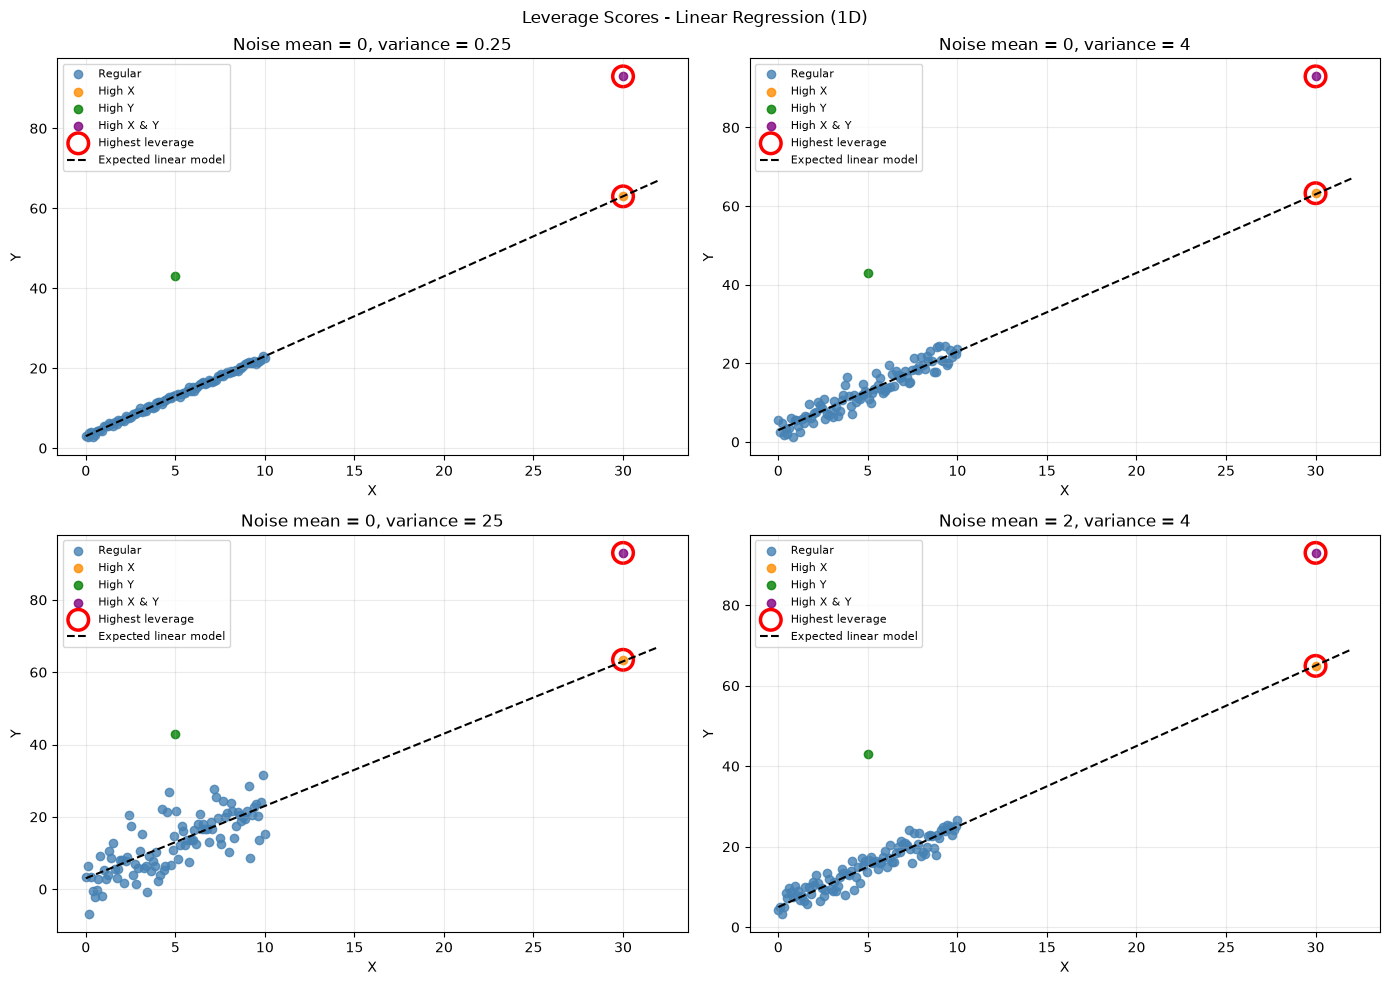


2D: Mean=0, variance=0.25
High X: leverage=0.3809
High Y: leverage=0.0100
High X & Y: leverage=0.3809

2D: Mean=0, variance=4
High X: leverage=0.3814
High Y: leverage=0.0102
High X & Y: leverage=0.3814

2D: Mean=0, variance=25
High X: leverage=0.3863
High Y: leverage=0.0100
High X & Y: leverage=0.3863

2D: Mean=2, variance=4
High X: leverage=0.3770
High Y: leverage=0.0100
High X & Y: leverage=0.3770


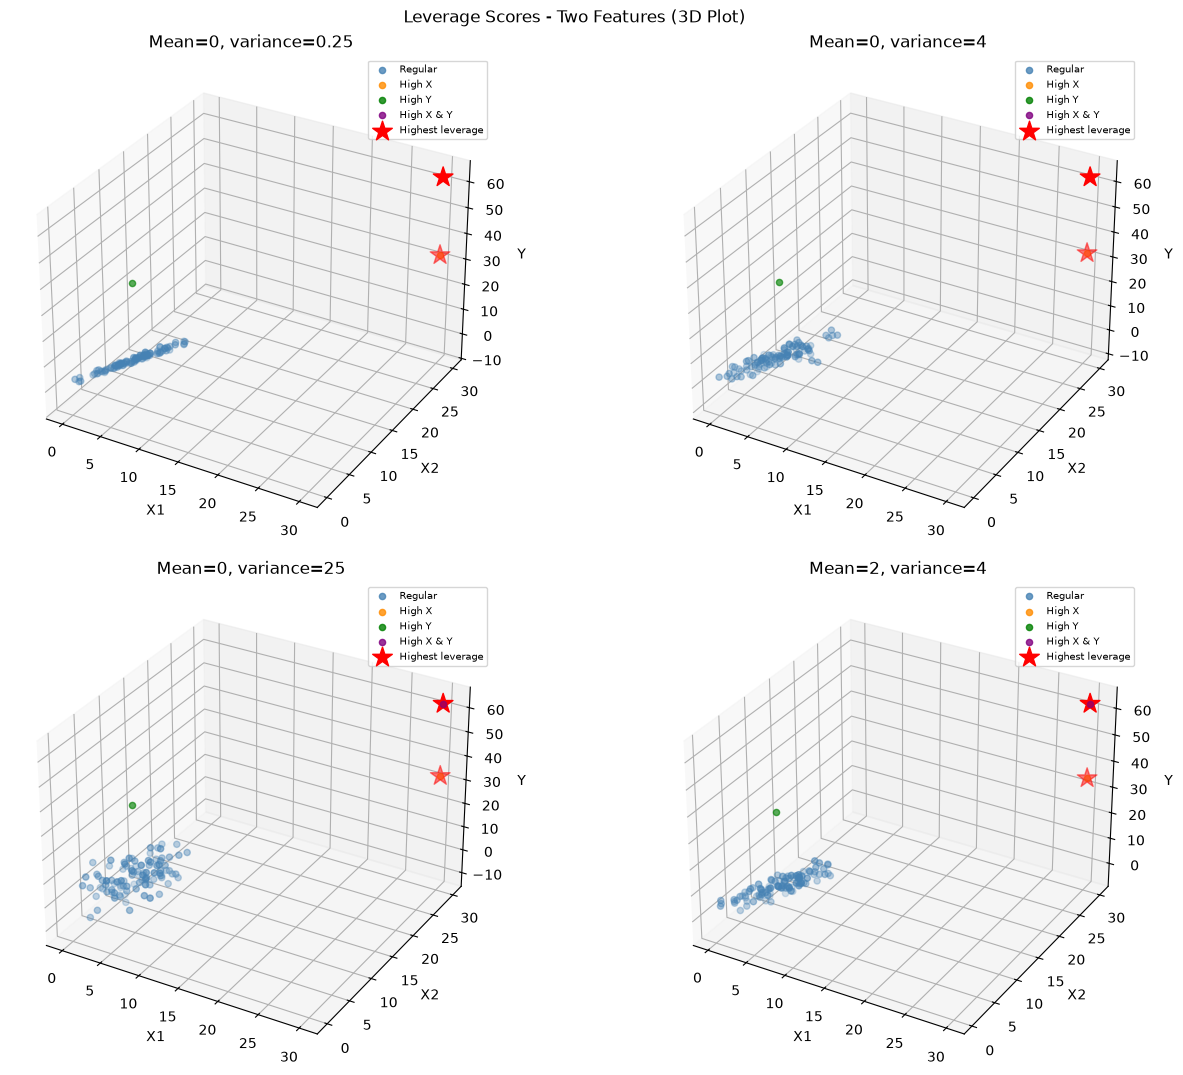

In [33]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

a = 2
b = 3
n_regular = 100

def leverage_1d(x):
    mean_x = np.mean(x)
    squared_dev = (x - mean_x) ** 2
    return 1 / x.size + squared_dev / np.sum(squared_dev)


def generate_1d(noise_mean, noise_std):

    x_regular = np.linspace(0, 10, n_regular)
    e_regular = rng.normal(
        loc=noise_mean, scale=noise_std, size=n_regular
    )
    y_regular = a * x_regular + b + e_regular

    x_high_x = np.array([30.0])
    y_high_x = a * x_high_x + b + rng.normal(
        noise_mean, noise_std * 0.1, size=1
    )

    x_high_y = np.array([5.0])
    y_high_y = a * x_high_y + b + 30.0

    x_high_both = np.array([30.0])
    y_high_both = a * x_high_both + b + 30.0

    x = np.concatenate([
        x_regular, x_high_x, x_high_y, x_high_both
    ])
    y = np.concatenate([
        y_regular, y_high_x, y_high_y, y_high_both
    ])

    groups = np.array(
        ["Regular"] * n_regular
        + ["High X", "High Y", "High X & Y"]
    )

    return x, y, groups


noise_settings = [
    (0, 0.5),
    (0, 2),
    (0, 5),
    (2, 2),
]

colors = {
    "Regular": "steelblue",
    "High X": "darkorange",
    "High Y": "green",
    "High X & Y": "purple",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (mu, sigma) in zip(axes.flat, noise_settings):
    x, y, groups = generate_1d(mu, sigma)
    scores = leverage_1d(x)

    for group, color in colors.items():
        mask = groups == group
        ax.scatter(
            x[mask], y[mask],
            color=color, label=group, alpha=0.8
        )

    max_score = np.max(scores)
    high_idx = np.where(np.isclose(scores, max_score))[0]

    ax.scatter(
        x[high_idx], y[high_idx],
        facecolors="none",
        edgecolors="red",
        s=220,
        linewidths=2.5,
        label="Highest leverage"
    )

    x_line = np.linspace(0, 32, 100)
    ax.plot(
        x_line,
        a * x_line + b + mu,
        "--", color="black",
        label="Expected linear model"
    )

    ax.set_title(
        f"Noise mean = {mu}, variance = {sigma**2:g}"
    )
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

    print(f"\nMean={mu}, variance={sigma**2:g}")
    for name, score in zip(groups[-3:], scores[-3:]):
        print(f"{name}: leverage={score:.4f}")

plt.suptitle("Leverage Scores - Linear Regression (1D)")
plt.tight_layout()
plt.show()

a2 = 2
b2 = -1
c2 = 3


def leverage_2d(x1, x2):
    X = np.column_stack([
        np.ones(len(x1)), x1, x2
    ])

    H = X @ np.linalg.pinv(X)

    return np.diag(H)


def generate_2d(noise_mean, noise_std):
    x1_regular = rng.uniform(0, 10, n_regular)
    x2_regular = rng.uniform(0, 10, n_regular)

    e_regular = rng.normal(
        noise_mean, noise_std, n_regular
    )

    y_regular = (
        a2 * x1_regular
        + b2 * x2_regular
        + c2
        + e_regular
    )

    x1_high_x = 30.0
    x2_high_x = 30.0
    y_high_x = (
        a2 * x1_high_x + b2 * x2_high_x + c2
        + rng.normal(noise_mean, noise_std * 0.1)
    )

    x1_high_y = 5.0
    x2_high_y = 5.0
    y_high_y = a2 * x1_high_y + b2 * x2_high_y + c2 + 30

    x1_high_both = 30.0
    x2_high_both = 30.0
    y_high_both = (
        a2 * x1_high_both + b2 * x2_high_both + c2 + 30
    )

    x1 = np.append(
        x1_regular,
        [x1_high_x, x1_high_y, x1_high_both]
    )
    x2 = np.append(
        x2_regular,
        [x2_high_x, x2_high_y, x2_high_both]
    )
    y = np.append(
        y_regular,
        [y_high_x, y_high_y, y_high_both]
    )

    groups = np.array(
        ["Regular"] * n_regular
        + ["High X", "High Y", "High X & Y"]
    )

    return x1, x2, y, groups


fig = plt.figure(figsize=(14, 11))

for i, (mu, sigma) in enumerate(noise_settings):
    x1, x2, y, groups = generate_2d(mu, sigma)
    scores = leverage_2d(x1, x2)

    ax = fig.add_subplot(2, 2, i + 1, projection="3d")

    for group, color in colors.items():
        mask = groups == group
        ax.scatter(
            x1[mask], x2[mask], y[mask],
            color=color, label=group, alpha=0.8
        )

    max_score = np.max(scores)
    high_idx = np.where(np.isclose(scores, max_score))[0]

    ax.scatter(
        x1[high_idx],
        x2[high_idx],
        y[high_idx],
        s=220,
        color="red",
        marker="*",
        label="Highest leverage"
    )

    ax.set_title(
        f"Mean={mu}, variance={sigma**2:g}"
    )
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_zlabel("Y")
    ax.legend(fontsize=7)

    print(f"\n2D: Mean={mu}, variance={sigma**2:g}")
    for name, score in zip(groups[-3:], scores[-3:]):
        print(f"{name}: leverage={score:.4f}")

plt.suptitle("Leverage Scores - Two Features (3D Plot)")
plt.tight_layout()
plt.show()


Ex. 2
Using the function generate data clusters generate a 2-dimensional dataset
with 400 train samples and 200 test samples that are organized in 2 clusters,
with 0.1 contamination. Train a KNN model from pyod.models.knn. Use 4
subplots in order to display using different colors (for inliers and outliers):
• Ground truth labels for training data
• Predicted labels for training data
• Ground truth labels for test data
• Predicted labels for test data
Use different values for the n neighbors parameter and observe how this
affects the detection of small clusters of anomalies. Also compute the balanced
accuracy for each parameter.

K = 3
Train BA: 0.9606291188260072
Test BA: 1.0



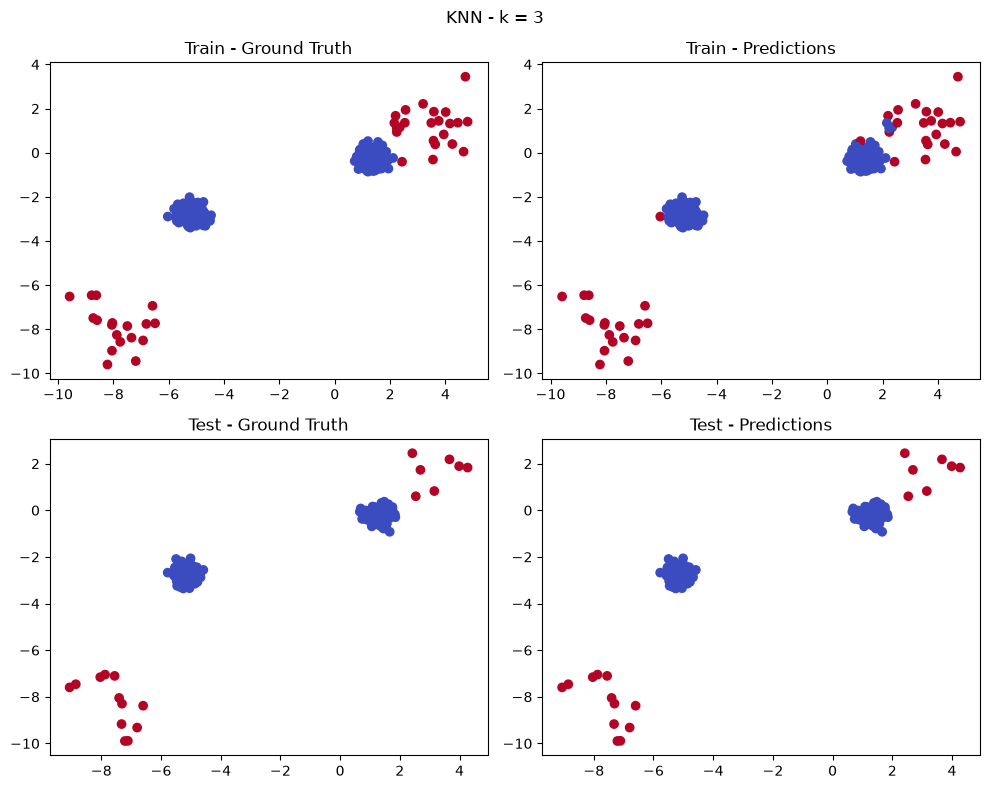

K = 5
Train BA: 0.9878048780487805
Test BA: 1.0



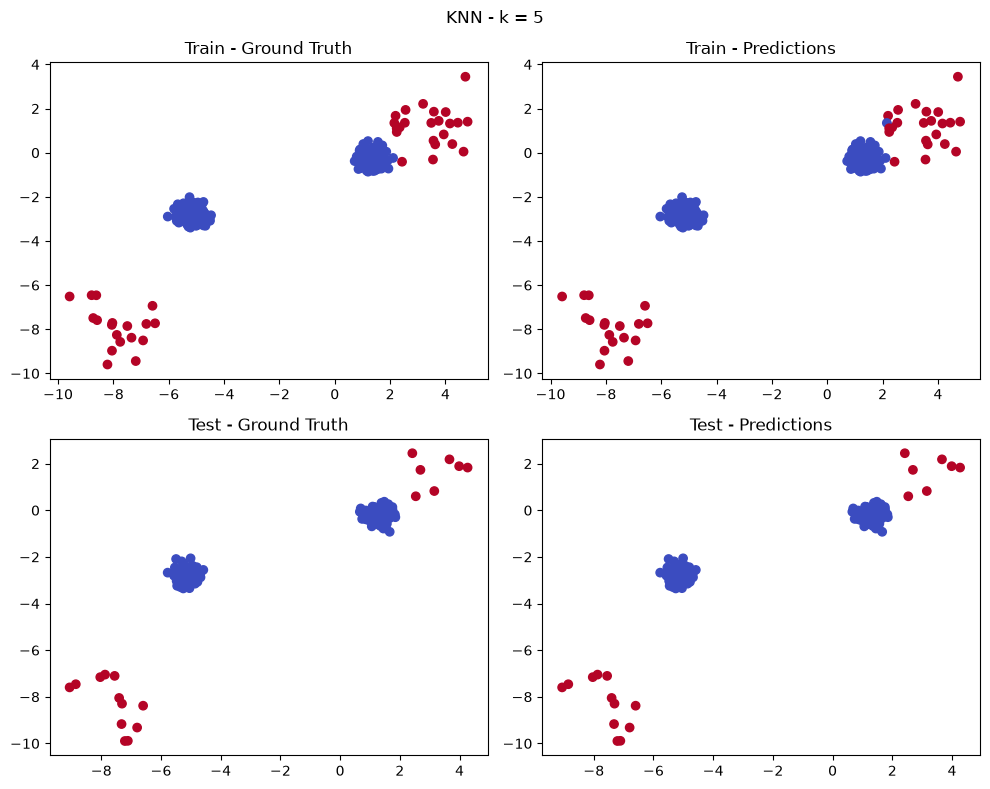

K = 10
Train BA: 0.9878048780487805
Test BA: 1.0



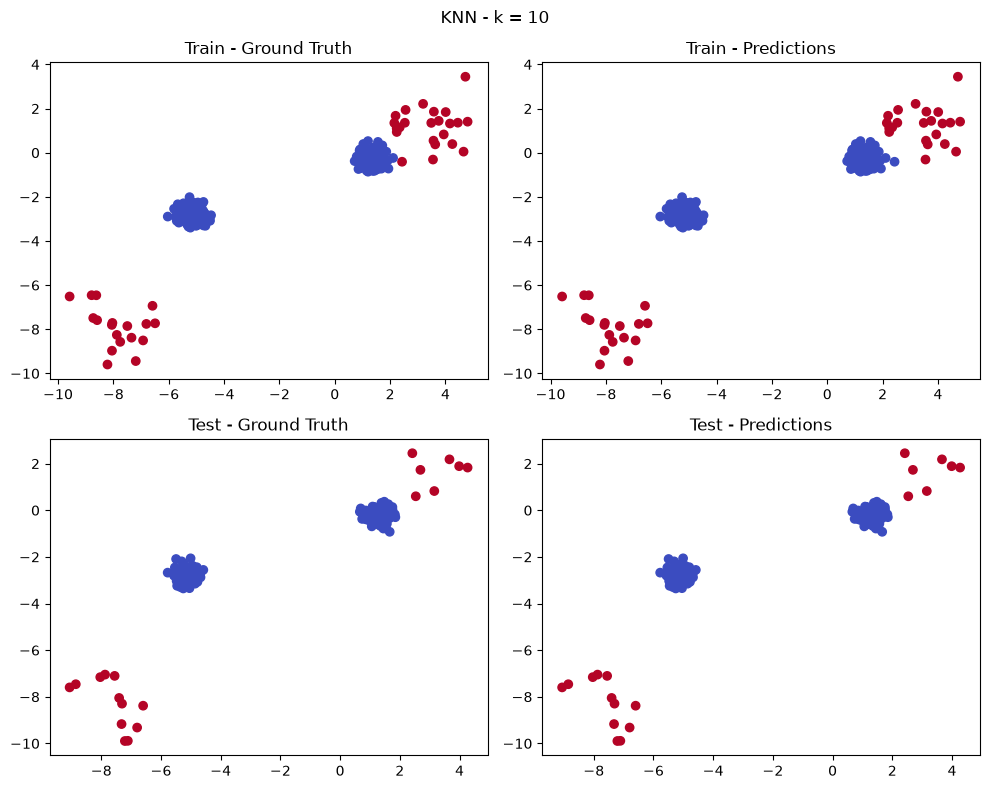

K = 20
Train BA: 0.9878048780487805
Test BA: 1.0



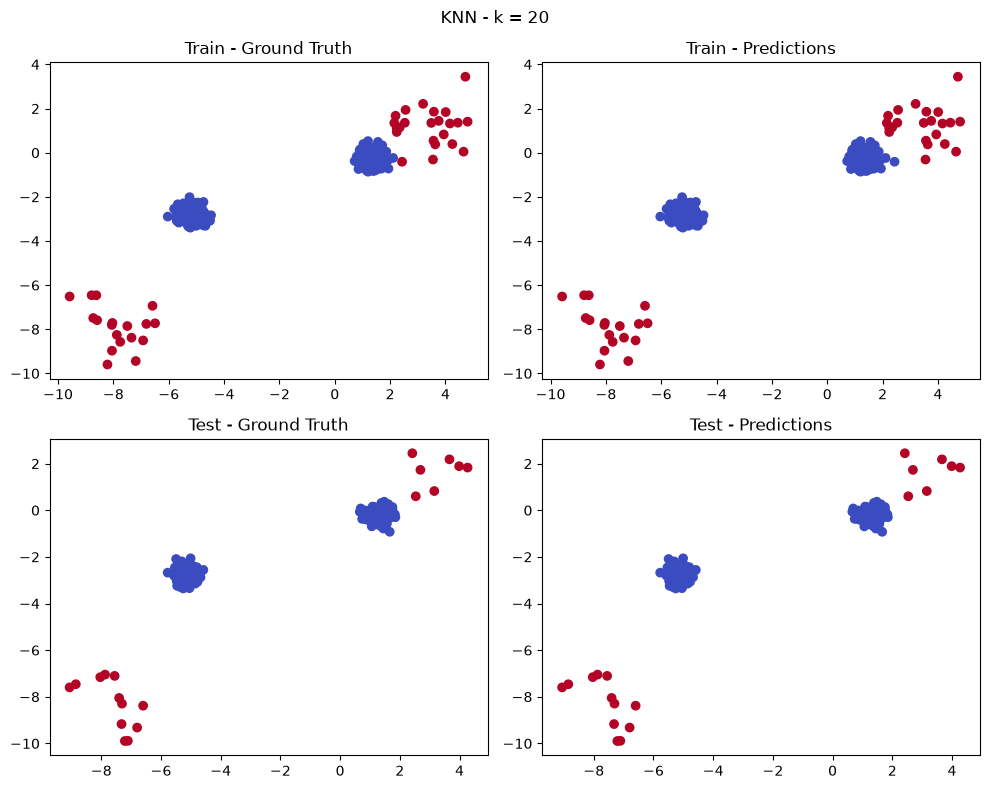

In [ ]:
import matplotlib.pyplot as plt
from pyod.utils.data import generate_data_clusters
from pyod.models.knn import KNN
from sklearn.metrics import balanced_accuracy_score

X_train, X_test, y_train, y_test = generate_data_clusters(
    n_train=400,
    n_test=200,
    n_clusters=2,
    n_features=2,
    contamination=0.1,
    random_state=42
)

for k in [3, 5, 10, 20]:

    model = KNN(n_neighbors=k, contamination=0.1)
    model.fit(X_train)

    train_pred = model.labels_
    test_pred = model.predict(X_test)

    train_ba = balanced_accuracy_score(y_train, train_pred)
    test_ba = balanced_accuracy_score(y_test, test_pred)

    print("K =", k)
    print("Train BA:", train_ba)
    print("Test BA:", test_ba)
    print()

    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    axes[0, 0].scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm")
    axes[0, 0].set_title("Train - Ground Truth")

    axes[0, 1].scatter(X_train[:, 0], X_train[:, 1], c=train_pred, cmap="coolwarm")
    axes[0, 1].set_title("Train - Predictions")

    axes[1, 0].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm")
    axes[1, 0].set_title("Test - Ground Truth")

    axes[1, 1].scatter(X_test[:, 0], X_test[:, 1], c=test_pred, cmap="coolwarm")
    axes[1, 1].set_title("Test - Predictions")

    fig.suptitle(f"KNN - k = {k}")
    plt.tight_layout()
    plt.show()


Ex. 3
In this exercise we will see the limitations of distance based algorithms like
KNN. Specifically, we will observe how KNN behaves when our data clusters
have different densities and how pyod.models.lof.LOF solves the problem by
considering the variations of the local densities of the datapoints. First, generate
2 clusters (200 and 100 samples respectively) with 2-dimensional samples using
(-10, -10) and (10, 10) as centers, 2 and 6 as standard deviations using
sklearn.datasets.make blobs() function. Then, fit KNN and LOF with the
generated data using a small contamination rate (0.07) and find the predicted
labels. Use 2 subplots to plot (using different colors for inliers and outliers) the
2 clusters and observe how the 2 models behave for different n neighbors.

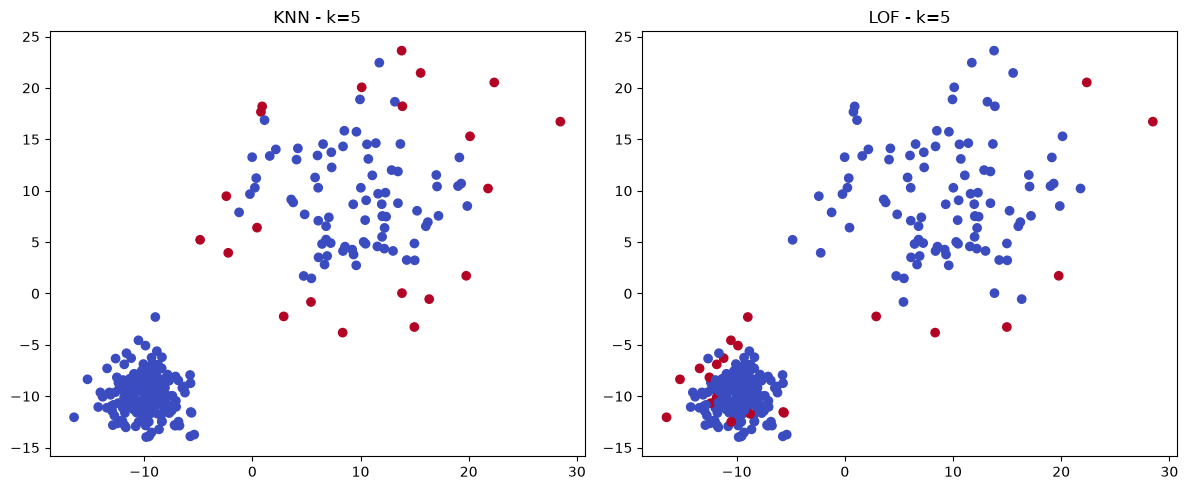

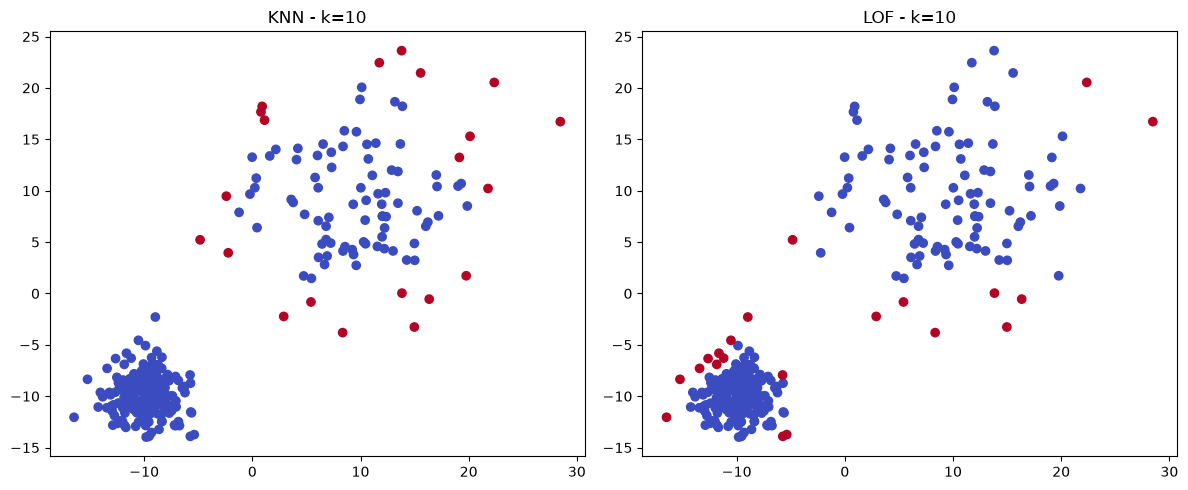

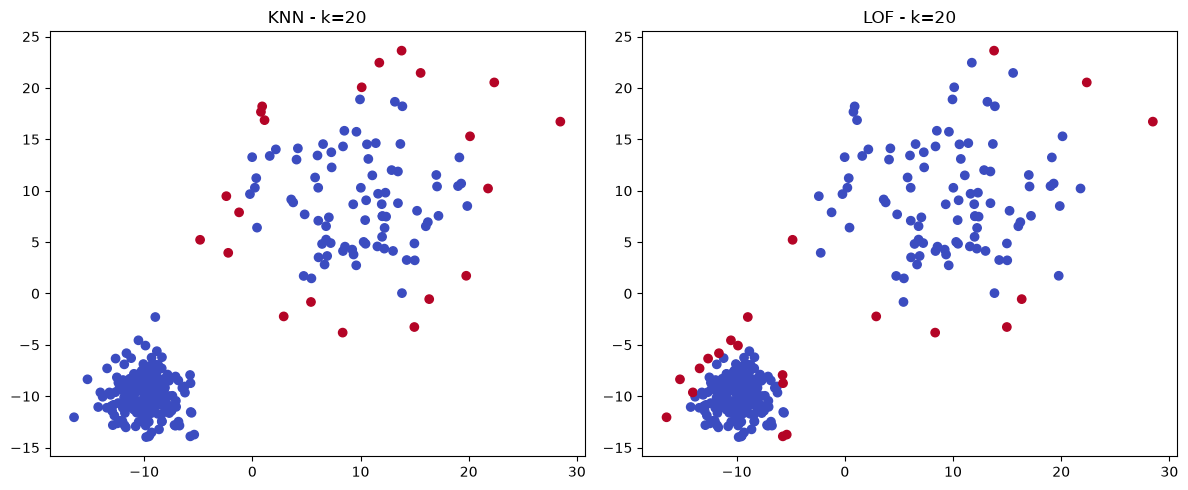

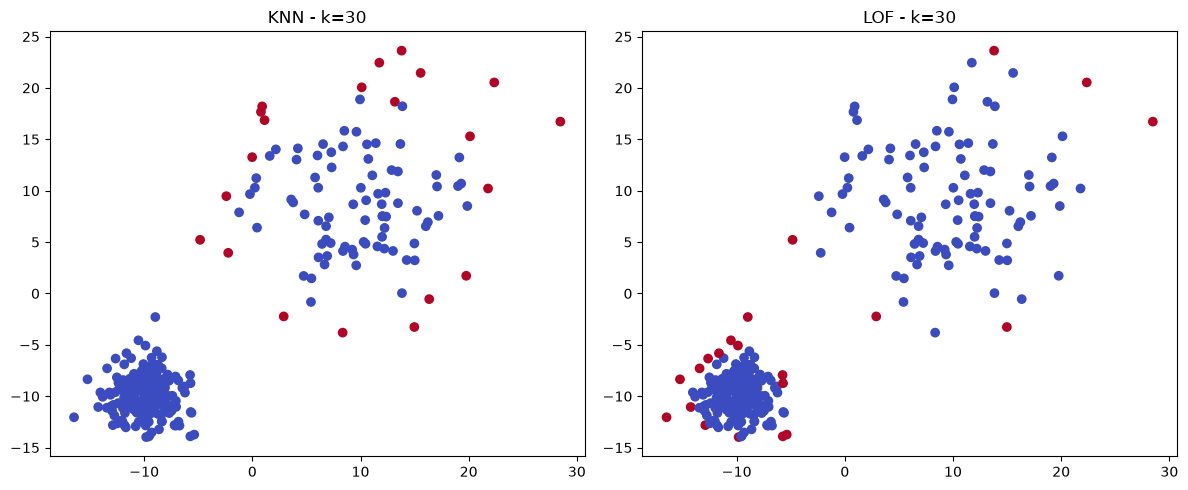

In [35]:

import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from pyod.models.knn import KNN
from pyod.models.lof import LOF

X, y = make_blobs(
    n_samples=[200, 100],
    centers=[(-10, -10), (10, 10)],
    cluster_std=[2, 6],
    n_features=2,
    random_state=42
)

for k in [5, 10, 20, 30]:

    knn = KNN(n_neighbors=k, contamination=0.07)
    lof = LOF(n_neighbors=k, contamination=0.07)
    
    knn.fit(X)
    lof.fit(X)

    knn_pred = knn.labels_
    lof_pred = lof.labels_

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(X[:, 0], X[:, 1], c=knn_pred, cmap="coolwarm")
    axes[0].set_title(f"KNN - k={k}")

    axes[1].scatter(X[:, 0], X[:, 1], c=lof_pred, cmap="coolwarm")
    axes[1].set_title(f"LOF - k={k}")

    plt.tight_layout()
    plt.show()


Ex. 4
For this exercise we will need the cardio dataset from ODDS (https://odds.cs.
stonybrook.edu/cardiotocogrpahy-dataset/). Load the data using scipy.io.loadmat()
and use train test split() to split it into train and test subsets. Normalize
your data accordingly. You will use an ensemble of classifiers of the same
type (KNN or LOF) in order to create an average/maximization strategy
(average/maximum score will be returned). Create 10 KNN/LOF models
for which you vary parameter n neighbors from 30 to 120 (here you can use
other intervals/steps if you observe that they produce better results). Fit each
model, print the balanced accuracy (BA) for train/test data and store both the
train and test scores in order to use them later. Normalize both scores using
pyod.utils.utility.standardizer() and use pyod.models.combination.average()
and pyod.models.combination.maximization() to find the final scores for
the 2 strategies. For each of them find the threshold used for classification
(using numpy.quantile() with the known contamination rate of the dataset),
compute the predictions and print the balanced accuracy (BA)

In [3]:
import numpy as np
from scipy.io import loadmat
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score
from pyod.models.knn import KNN
from pyod.utils.utility import standardizer
from pyod.models.combination import average, maximization

data = loadmat("cardio.mat")

X = data["X"]
y = data["y"].ravel()

contamination = np.mean(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

X_train, X_test = standardizer(X_train, X_test)

train_scores = []
test_scores = []

k_values = range(30, 121, 10)

for k in k_values:
    model = KNN(n_neighbors=k, contamination=contamination)
    model.fit(X_train)

    train_pred = model.labels_
    test_pred = model.predict(X_test)

    train_ba = balanced_accuracy_score(y_train, train_pred)
    test_ba = balanced_accuracy_score(y_test, test_pred)

    print(f"K={k} | Train BA={train_ba:.4f} | Test BA={test_ba:.4f}")

    train_scores.append(model.decision_scores_)
    test_scores.append(model.decision_function(X_test))

train_scores = np.array(train_scores).T
test_scores = np.array(test_scores).T

train_scores, test_scores = standardizer(train_scores, test_scores)

train_avg = average(train_scores)
test_avg = average(test_scores)

threshold_avg = np.quantile(train_avg, 1 - contamination)

train_pred_avg = (train_avg > threshold_avg).astype(int)
test_pred_avg = (test_avg > threshold_avg).astype(int)

print("\nAVERAGE")
print("Train BA:", balanced_accuracy_score(y_train, train_pred_avg))
print("Test BA:", balanced_accuracy_score(y_test, test_pred_avg))

train_max = maximization(train_scores)
test_max = maximization(test_scores)

threshold_max = np.quantile(train_max, 1 - contamination)

train_pred_max = (train_max > threshold_max).astype(int)
test_pred_max = (test_max > threshold_max).astype(int)

print("\nMAXIMIZATION")
print("Train BA:", balanced_accuracy_score(y_train, train_pred_max))
print("Test BA:", balanced_accuracy_score(y_test, test_pred_max))


K=30 | Train BA=0.7073 | Test BA=0.6740
K=40 | Train BA=0.7163 | Test BA=0.6864
K=50 | Train BA=0.7253 | Test BA=0.7147
K=60 | Train BA=0.7253 | Test BA=0.7242
K=70 | Train BA=0.7343 | Test BA=0.7430
K=80 | Train BA=0.7477 | Test BA=0.7525
K=90 | Train BA=0.7522 | Test BA=0.7525
K=100 | Train BA=0.7522 | Test BA=0.7525
K=110 | Train BA=0.7477 | Test BA=0.7535
K=120 | Train BA=0.7522 | Test BA=0.7639

AVERAGE
Train BA: 0.7297590462951262
Test BA: 0.7430241828328461

MAXIMIZATION
Train BA: 0.7522431441930999
Test BA: 0.752458145096997
